## Cross-Validation & Error Analysis


## 1. Imports and paths

In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "tehran_house_prices_cleaned.csv"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}" 

Project root: D:\python\tehran-house-price-prediction
Dataset exists: True


## 2. Load data and define features
We exclude derived price columns to avoid target leakage.

In [7]:
df = pd.read_csv(DATA_PATH)

TARGET = "Price"
NUMERIC_FEATURES = ["Area", "Room"]
BOOLEAN_FEATURES = ["Parking", "Warehouse", "Elevator"]
CATEGORICAL_FEATURES = ["Address"]
FEATURES = NUMERIC_FEATURES + BOOLEAN_FEATURES + CATEGORICAL_FEATURES

required = FEATURES + [TARGET]
missing_columns = [c for c in required if c not in df.columns]
assert not missing_columns, f"Missing columns: {missing_columns}"

df = df[required].copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET])
df = df[df[TARGET] > 0].copy()
df["Address"] = df["Address"].fillna("Unknown").astype(str)

X = df[FEATURES]
y = df[TARGET]

print("Rows used:", len(df))
print("Feature columns:", FEATURES)
print("Target: total house price in rials")
display(df.head())

Rows used: 3256
Feature columns: ['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address']
Target: total house price in rials


,Area,Room,Parking,Warehouse,Elevator,Address,Price
0,63,1,True,True,True,Shahran,1.850000e+09
1,60,1,True,True,True,Shahran,1.850000e+09
2,79,2,True,True,True,Pardis,5.500000e+08
3,95,2,True,True,True,Shahrake Qods,9.025000e+08
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09


## 3. Make the fixed train/test split
The test set is held aside for final evaluation. Cross-validation uses only the training set.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 2604
Test rows: 652


## 4. Build preprocessing and baseline models

In [9]:
numeric_transformer = SimpleImputer(strategy="median")

boolean_transformer = Pipeline(steps=[
    ("to_numeric", FunctionTransformer(
        lambda x: x.astype("float64"), feature_names_out="one-to-one"
    )),
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, NUMERIC_FEATURES),
    ("bool", boolean_transformer, BOOLEAN_FEATURES),
    ("cat", categorical_transformer, CATEGORICAL_FEATURES)
])

models = {
    "Dummy median baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42, min_samples_leaf=5
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, min_samples_leaf=2, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42, n_estimators=100, learning_rate=0.05, max_depth=2
    ),
}

print("Models ready:", ", ".join(models.keys()))

Models ready: Dummy median baseline, Linear Regression, Decision Tree, Random Forest, Gradient Boosting


## 5. Five-fold cross-validation on training data
Each fold uses a different part of the training data for validation. Lower MAE/RMSE is better; higher R² is better.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

cv_rows = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "CV_MAE_rials": -scores["test_mae"].mean(),
        "CV_RMSE_rials": -scores["test_rmse"].mean(),
        "CV_R2": scores["test_r2"].mean(),
        "CV_RMSE_std": scores["test_rmse"].std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV_RMSE_rials").reset_index(drop=True)
display(cv_results)
cv_results.to_csv(REPORTS_DIR / "day5_cross_validation_results.csv", index=False)
print("Saved:", REPORTS_DIR / "day5_cross_validation_results.csv")

,Model,CV_MAE_rials,CV_RMSE_rials,CV_R2,CV_RMSE_std
0,Random Forest,1.694540e+09,4.176413e+09,0.742667,7.948519e+08
1,Linear Regression,2.024214e+09,4.408231e+09,0.709553,5.467469e+08
2,Gradient Boosting,2.182162e+09,4.541644e+09,0.693069,7.317713e+08
3,Decision Tree,1.918325e+09,4.555554e+09,0.694056,1.011199e+09
4,Dummy median baseline,3.975871e+09,8.574073e+09,-0.090963,8.694791e+08


Saved: D:\python\tehran-house-price-prediction\reports\day5_cross_validation_results.csv


## 6. Fit models on all training data and evaluate once on the test set

In [11]:
fitted_models = {}
test_predictions = {}
test_rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    test_predictions[name] = pred
    test_rows.append({
        "Model": name,
        "Test_MAE_rials": mean_absolute_error(y_test, pred),
        "Test_RMSE_rials": mean_squared_error(y_test, pred) ** 0.5,
        "Test_R2": r2_score(y_test, pred),
    })

test_results = pd.DataFrame(test_rows).sort_values("Test_RMSE_rials").reset_index(drop=True)
display(test_results)
test_results.to_csv(REPORTS_DIR / "day5_test_results.csv", index=False)
print("Saved:", REPORTS_DIR / "day5_test_results.csv")

,Model,Test_MAE_rials,Test_RMSE_rials,Test_R2
0,Gradient Boosting,2.250352e+09,4.975560e+09,0.589141
1,Random Forest,1.912439e+09,5.105464e+09,0.567407
2,Decision Tree,2.113373e+09,5.298891e+09,0.534007
3,Linear Regression,2.268592e+09,6.018679e+09,0.398811
4,Dummy median baseline,3.924260e+09,8.157601e+09,-0.104419


Saved: D:\python\tehran-house-price-prediction\reports\day5_test_results.csv


## 7. Compare cross-validation and test RMSE

,Model,CV_RMSE_rials,Test_RMSE_rials
0,Random Forest,4.176413e+09,5.105464e+09
1,Linear Regression,4.408231e+09,6.018679e+09
2,Gradient Boosting,4.541644e+09,4.975560e+09
3,Decision Tree,4.555554e+09,5.298891e+09
4,Dummy median baseline,8.574073e+09,8.157601e+09


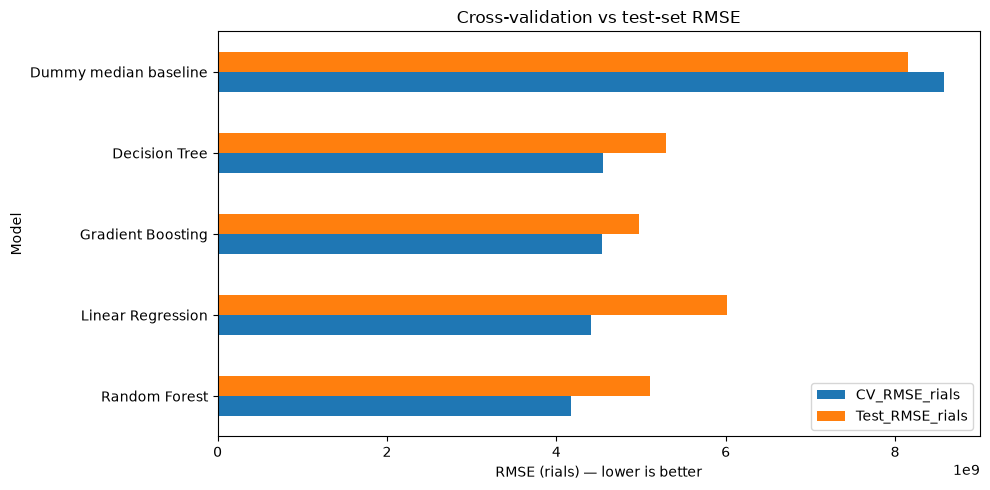

Saved: D:\python\tehran-house-price-prediction\figures\day5_cv_vs_test_rmse.png


In [12]:
comparison = cv_results[["Model", "CV_RMSE_rials"]].merge(
    test_results[["Model", "Test_RMSE_rials"]], on="Model"
).sort_values("CV_RMSE_rials")

display(comparison)

plot_data = comparison.set_index("Model")[["CV_RMSE_rials", "Test_RMSE_rials"]]
ax = plot_data.plot(kind="barh", figsize=(10, 5))
ax.set_xlabel("RMSE (rials) — lower is better")
ax.set_title("Cross-validation vs test-set RMSE")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "day5_cv_vs_test_rmse.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", FIGURES_DIR / "day5_cv_vs_test_rmse.png")

## 8. Error analysis for the best test-set model
Residual = actual price − predicted price. Large absolute residuals mean large prediction errors.

In [13]:
best_model_name = test_results.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_pred = test_predictions[best_model_name]

errors = pd.DataFrame({
    "Actual_Price_rials": y_test.to_numpy(),
    "Predicted_Price_rials": best_pred,
})
errors["Residual_rials"] = errors["Actual_Price_rials"] - errors["Predicted_Price_rials"]
errors["Absolute_Error_rials"] = errors["Residual_rials"].abs()
errors["Absolute_Percent_Error"] = (
    errors["Absolute_Error_rials"] / errors["Actual_Price_rials"].clip(lower=1) * 100
)

print("Best model by test RMSE:", best_model_name)
print("Test MAE (rials):", round(mean_absolute_error(y_test, best_pred), 2))
print("Test RMSE (rials):", round(mean_squared_error(y_test, best_pred) ** 0.5, 2))
print("Test R²:", round(r2_score(y_test, best_pred), 4))

display(errors.sort_values("Absolute_Error_rials", ascending=False).head(10))
errors.to_csv(REPORTS_DIR / "day5_best_model_errors.csv", index=False)
print("Saved:", REPORTS_DIR / "day5_best_model_errors.csv")

Best model by test RMSE: Gradient Boosting
Test MAE (rials): 2250352390.46
Test RMSE (rials): 4975559701.54
Test R²: 0.5891


,Actual_Price_rials,Predicted_Price_rials,Residual_rials,Absolute_Error_rials,Absolute_Percent_Error
129,3.500000e+09,6.158392e+10,-5.808392e+10,5.808392e+10,1659.540442
306,7.440000e+10,2.593500e+10,4.846500e+10,4.846500e+10,65.141131
118,8.050000e+10,3.831349e+10,4.218651e+10,4.218651e+10,52.405607
533,9.000000e+09,3.486401e+10,-2.586401e+10,2.586401e+10,287.377934
97,4.500000e+09,2.867604e+10,-2.417604e+10,2.417604e+10,537.245259
161,4.319700e+10,2.210020e+10,2.109680e+10,2.109680e+10,48.838576
534,3.850000e+09,2.421422e+10,-2.036422e+10,2.036422e+10,528.940804
169,1.700000e+10,3.529091e+10,-1.829091e+10,1.829091e+10,107.593577
277,4.550000e+10,2.753578e+10,1.796422e+10,1.796422e+10,39.481797
448,1.750000e+09,1.966377e+10,-1.791377e+10,1.791377e+10,1023.644106


Saved: D:\python\tehran-house-price-prediction\reports\day5_best_model_errors.csv


## 9. Diagnostic plots

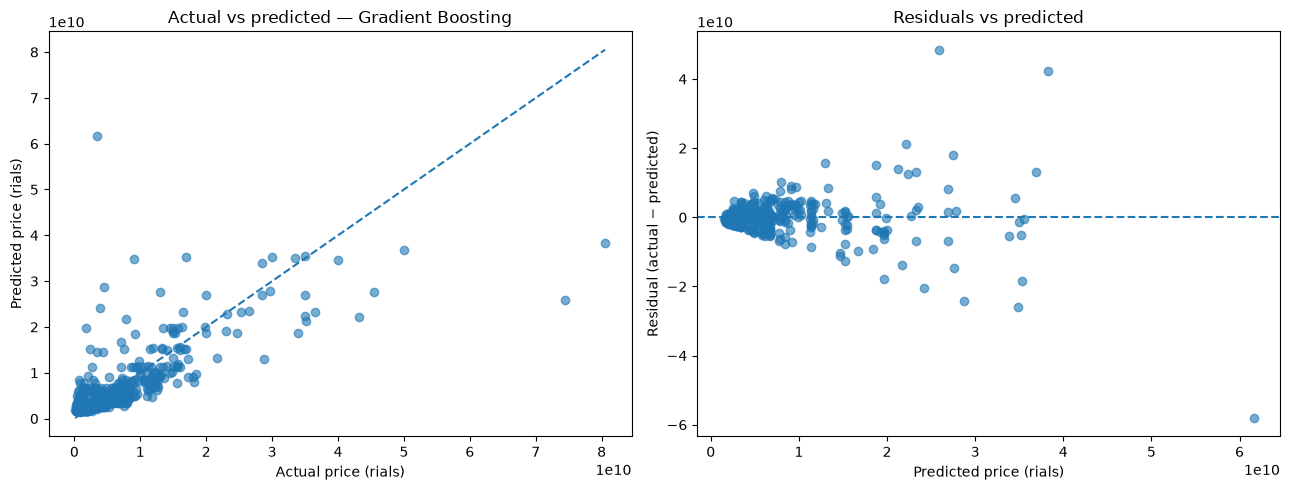

Saved: D:\python\tehran-house-price-prediction\figures\day5_error_diagnostics.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(errors["Actual_Price_rials"], errors["Predicted_Price_rials"], alpha=0.6)
low = min(errors["Actual_Price_rials"].min(), errors["Predicted_Price_rials"].min())
high = max(errors["Actual_Price_rials"].max(), errors["Predicted_Price_rials"].max())
axes[0].plot([low, high], [low, high], linestyle="--")
axes[0].set_xlabel("Actual price (rials)")
axes[0].set_ylabel("Predicted price (rials)")
axes[0].set_title(f"Actual vs predicted — {best_model_name}")

axes[1].scatter(errors["Predicted_Price_rials"], errors["Residual_rials"], alpha=0.6)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Predicted price (rials)")
axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residuals vs predicted")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "day5_error_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", FIGURES_DIR / "day5_error_diagnostics.png")

**Day 5 Results**

- **Best model by cross-validation RMSE:** Random Forest — approximately 4.18 billion rials.
- **Best model by test RMSE:** Gradient Boosting — approximately 4.98 billion rials.
- **CV vs test comparison:** Random Forest's test RMSE (5.11 billion rials) is higher than its cross-validation RMSE. The difference suggests some variation in model performance across data splits.
- **Residual plot observation:** The model makes some large prediction errors, especially for unusually cheap or expensive houses. Predictions are less reliable for extreme prices.
- **Next improvement and reason:** Feature engineering. Adding more useful location-related features could help the models capture differences between Tehran neighborhoods and improve prediction accuracy.